# 05.06 Final Selected Model Evaluation & Verification

**Phase 05 — Model Selection & Training**  
**Objective:** Execute final evaluation of the selected model on the untouched test partition, compute calibration curves, confusion matrix, and export thesis-ready evaluation artifacts.


### Research Objectives

1. Verify test set quarantine integrity and unseal the final test partition ($N=75$).
2. Load champion model architecture and hyperparameter specifications from `models/trained/model_comparison_summary.json`.
3. Train champion model on the complete development training partition ($N=350$).
4. Generate test set predictions and evaluate Test Accuracy, Precision, Recall, Macro F1, Weighted F1, and ROC-AUC.
5. Produce the 11 required final test-set visualization graphs:
   - **Graph 1:** Final Confusion Matrix (raw counts).
   - **Graph 2:** Normalized Confusion Matrix.
   - **Graph 3:** Per-Class Precision, Recall, and F1-score.
   - **Graph 4:** Test ROC Curve and AUC.
   - **Graph 5:** Test Precision-Recall Curve.
   - **Graph 6:** Final Model Performance Summary Dashboard.
   - **Graph 7:** Actual vs Predicted Class Distribution.
   - **Graph 8:** Prediction Confidence Distribution.
   - **Graph 9:** False Positive and False Negative Error Analysis.
   - **Graph 10:** 10-Fold CV Mean vs Final Test Performance.
   - **Graph 11:** Generalization Gap Analysis.
6. Export final test report to `models/trained/final_test_evaluation_report.json` and high-res figures to `reports/phase_05/visualizations/final_model_evaluation/`.

### Inputs & Expected Outputs

**Required Inputs:**
- `data/interim/features/selected_features.csv` (Full dataset with `split_partition == 'test'` and `'train'`)
- `models/trained/model_comparison_summary.json` (Designated champion model architecture and parameters)

**Expected Outputs:**
- `models/trained/final_test_evaluation_report.json`
- `reports/phase_05/visualizations/final_model_evaluation/graph1_final_confusion_matrix.{png,pdf}`
- `reports/phase_05/visualizations/final_model_evaluation/graph2_normalized_confusion_matrix.{png,pdf}`
- `reports/phase_05/visualizations/final_model_evaluation/graph3_per_class_metrics.{png,pdf}`
- `reports/phase_05/visualizations/final_model_evaluation/graph4_test_roc_curve.{png,pdf}`
- `reports/phase_05/visualizations/final_model_evaluation/graph5_test_pr_curve.{png,pdf}`
- `reports/phase_05/visualizations/final_model_evaluation/graph6_performance_summary.{png,pdf}`
- `reports/phase_05/visualizations/final_model_evaluation/graph7_actual_vs_predicted_distribution.{png,pdf}`
- `reports/phase_05/visualizations/final_model_evaluation/graph8_prediction_confidence_distribution.{png,pdf}`
- `reports/phase_05/visualizations/final_model_evaluation/graph9_error_case_analysis.{png,pdf}`
- `reports/phase_05/visualizations/final_model_evaluation/graph10_cv_vs_test_comparison.{png,pdf}`
- `reports/phase_05/visualizations/final_model_evaluation/graph11_generalization_gap.{png,pdf}`
- `reports/phase_05/visualizations/final_model_evaluation/final_test_summary_table.csv`

### 1. Environment Setup & Library Imports

In [1]:
import json
import time
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, precision_recall_curve, average_precision_score,
    confusion_matrix, classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.sans-serif"] = ["DejaVu Sans", "Arial", "Helvetica"]
plt.rcParams["axes.edgecolor"] = "#333333"
plt.rcParams["axes.linewidth"] = 0.8
print("Libraries loaded successfully.")


/home/kristoper/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-__2vr86n because there was an issue with the default path (/home/kristoper/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


Libraries loaded successfully.


### 2. Verify Quarantine Integrity and Load Champion Configuration

In [2]:
def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'data').exists() and (p / 'experiments').exists():
            return p
    return Path('../../..').resolve()

PROJECT_ROOT = _find_project_root(Path.cwd())
FEATURES_PATH = PROJECT_ROOT / "data" / "interim" / "features" / "selected_features.csv"
CV_PATH = PROJECT_ROOT / "data" / "processed" / "splits" / "cv_split_indices.json"
SUMMARY_PATH = PROJECT_ROOT / "models" / "trained" / "model_comparison_summary.json"
OUTPUT_DIR = PROJECT_ROOT / "models" / "trained"
REPORT_VIZ_DIR = PROJECT_ROOT / "reports" / "phase_05" / "visualizations" / "final_model_evaluation"
REPORT_VIZ_DIR.mkdir(parents=True, exist_ok=True)

assert FEATURES_PATH.exists(), f"Missing dataset: {FEATURES_PATH}"
assert CV_PATH.exists(), f"Missing CV split file: {CV_PATH}"
assert SUMMARY_PATH.exists(), f"Missing comparison summary: {SUMMARY_PATH}"

with open(SUMMARY_PATH, "r", encoding="utf-8") as f:
    comp_summary = json.load(f)

champion_info = comp_summary.get("champion_selection", {})
champion_name = champion_info.get("champion_model")
print(f"Protocol Check: Identified Champion Model -> {champion_name}")
if champion_name is None:
    print("NOTICE: Champion model not yet designated in comparison summary. Run 07 notebook first.")


Protocol Check: Identified Champion Model -> CatBoost


### 3. Unseal Quarantined Test Partition and Development Training Set

In [3]:
df_features = pd.read_csv(FEATURES_PATH)
with open(CV_PATH, "r", encoding="utf-8") as f:
    cv_data = json.load(f)

feature_cols = cv_data["feature_columns"]

# Development set (Train N=350)
train_mask = df_features["split_partition"] == "train"
df_train = df_features.loc[train_mask].reset_index(drop=True)
X_train = df_train[feature_cols]
y_train = (df_train["eligibility"] == "ELIGIBLE").astype(int)

# Unsealed Final Test set (N=75)
test_mask = df_features["split_partition"] == "test"
df_test = df_features.loc[test_mask].reset_index(drop=True)
X_test = df_test[feature_cols]
y_test = (df_test["eligibility"] == "ELIGIBLE").astype(int)

print("TEST PARTITION UNSEALED UNDER CONTROLLED AUDIT LOGGING:")
print(f"  Training development samples: {len(X_train)} (Eligible: {y_train.sum()}, Ineligible: {(1 - y_train).sum()})")
print(f"  Quarantined test samples:    {len(X_test)} (Eligible: {y_test.sum()}, Ineligible: {(1 - y_test).sum()})")
print(f"  Predictor columns:           {len(feature_cols)}")


TEST PARTITION UNSEALED UNDER CONTROLLED AUDIT LOGGING:
  Training development samples: 730 (Eligible: 365, Ineligible: 365)
  Quarantined test samples:    157 (Eligible: 78, Ineligible: 79)
  Predictor columns:           41


### 4. Train Champion on Full Development Set & Execute Final Test Inference

In [4]:
def build_and_fit_champion(model_name, X_tr, y_tr):
    if "Logistic Regression" in model_name:
        from sklearn.linear_model import LogisticRegression
        pipe = Pipeline([("scaler", StandardScaler()), ("clf", LogisticRegression(C=1.0, max_iter=1000, random_state=RANDOM_SEED))])
        pipe.fit(X_tr, y_tr)
        return pipe
    elif "Decision Tree" in model_name:
        from sklearn.tree import DecisionTreeClassifier
        clf = DecisionTreeClassifier(max_depth=5, min_samples_split=5, random_state=RANDOM_SEED)
        clf.fit(X_tr, y_tr)
        return clf
    elif "Random Forest" in model_name:
        import joblib
        saved_rf = OUTPUT_DIR / 'baselines' / 'random_forest_model.joblib'
        if saved_rf.exists():
            clf = joblib.load(saved_rf)
            clf.fit(X_tr, y_tr)
            return clf
        from sklearn.ensemble import RandomForestClassifier
        clf = RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=RANDOM_SEED, outer_bags=4, n_jobs=1)
        clf.fit(X_tr, y_tr)
        return clf
    elif "SVM" in model_name or "Support Vector" in model_name:
        from sklearn.svm import SVC
        pipe = Pipeline([("scaler", StandardScaler()), ("clf", SVC(C=1.0, kernel="rbf", probability=True, random_state=RANDOM_SEED))])
        pipe.fit(X_tr, y_tr)
        return pipe
    elif "XGBoost" in model_name:
        from xgboost import XGBClassifier
        clf = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.05, eval_metric="logloss", random_state=RANDOM_SEED, outer_bags=4, n_jobs=1)
        clf.fit(X_tr, y_tr)
        return clf
    elif "CatBoost" in model_name:
        import joblib
        saved_cb = OUTPUT_DIR / 'gradient_boosting' / 'catboost_model.joblib'
        if saved_cb.exists():
            clf = joblib.load(saved_cb)
            clf.fit(X_tr, y_tr)
            return clf
        from catboost import CatBoostClassifier
        clf = CatBoostClassifier(iterations=200, depth=4, learning_rate=0.05, auto_class_weights='Balanced', loss_function="Logloss", verbose=0, random_seed=RANDOM_SEED)
        clf.fit(X_tr, y_tr)
        return clf
    elif "Explainable Boosting" in model_name or "EBM" in model_name:
        import joblib
        saved_ebm = OUTPUT_DIR / 'interpretable' / 'ebm_model.joblib'
        if saved_ebm.exists():
            clf = joblib.load(saved_ebm)
            clf.fit(X_tr, y_tr)
            return clf
        from interpret.glassbox import ExplainableBoostingClassifier
        clf = ExplainableBoostingClassifier(interactions=5, max_bins=128, learning_rate=0.05, random_state=RANDOM_SEED, outer_bags=4, n_jobs=1)
        clf.fit(X_tr, y_tr)
        return clf
    else:
        raise ValueError(f"Unknown model: {model_name}")

if champion_name is not None:
    print(f"Training champion model ({champion_name}) on all {len(X_train)} development samples...")
    start_fit = time.time()
    champion_fitted = build_and_fit_champion(champion_name, X_train, y_train)
    train_latency_ms = (time.time() - start_fit) * 1000
    
    start_infer = time.time()
    test_preds = champion_fitted.predict(X_test)
    test_probs = champion_fitted.predict_proba(X_test)[:, 1]
    infer_latency_ms = ((time.time() - start_infer) / len(X_test)) * 1000
    import joblib
    joblib.dump(champion_fitted, OUTPUT_DIR / 'champion_model.joblib')
    
    t_acc = accuracy_score(y_test, test_preds)
    t_prec_macro = precision_score(y_test, test_preds, average="macro", zero_division=0)
    t_rec_macro = recall_score(y_test, test_preds, average="macro", zero_division=0)
    t_f1_macro = f1_score(y_test, test_preds, average="macro", zero_division=0)
    t_f1_weighted = f1_score(y_test, test_preds, average="weighted", zero_division=0)
    t_prec_c0 = precision_score(y_test, test_preds, pos_label=0, zero_division=0)
    t_rec_c0 = recall_score(y_test, test_preds, pos_label=0, zero_division=0)
    t_prec_c1 = precision_score(y_test, test_preds, pos_label=1, zero_division=0)
    t_rec_c1 = recall_score(y_test, test_preds, pos_label=1, zero_division=0)
    t_auc = roc_auc_score(y_test, test_probs)
    cm = confusion_matrix(y_test, test_preds)
    cm_norm = confusion_matrix(y_test, test_preds, normalize="true")
    
    test_metrics = {
        "accuracy": float(t_acc),
        "macro_precision": float(t_prec_macro),
        "macro_recall": float(t_rec_macro),
        "macro_f1": float(t_f1_macro),
        "weighted_f1": float(t_f1_weighted),
        "prec_ineligible": float(t_prec_c0),
        "rec_ineligible": float(t_rec_c0),
        "prec_eligible": float(t_prec_c1),
        "rec_eligible": float(t_rec_c1),
        "roc_auc": float(t_auc),
        "per_sample_inference_latency_ms": round(infer_latency_ms, 3),
        "confusion_matrix": cm.tolist()
    }
    print(f"\nFINAL TEST EVALUATION RESULTS ({champion_name}):")
    print(json.dumps(test_metrics, indent=2))
    print("\nClassification Report:")
    print(classification_report(y_test, test_preds, target_names=["INELIGIBLE", "ELIGIBLE"]))
else:
    test_metrics = {"status": "AWAITING_CHAMPION_SELECTION"}
    print("Awaiting champion selection in 07 notebook.")


Training champion model (CatBoost) on all 730 development samples...



FINAL TEST EVALUATION RESULTS (CatBoost):
{
  "accuracy": 0.8980891719745223,
  "macro_precision": 0.8990243902439025,
  "macro_recall": 0.8982473222979552,
  "macro_f1": 0.898051948051948,
  "weighted_f1": 0.8980395400777568,
  "prec_ineligible": 0.92,
  "rec_ineligible": 0.8734177215189873,
  "prec_eligible": 0.8780487804878049,
  "rec_eligible": 0.9230769230769231,
  "roc_auc": 0.9597533268419345,
  "per_sample_inference_latency_ms": 0.073,
  "confusion_matrix": [
    [
      69,
      10
    ],
    [
      6,
      72
    ]
  ]
}

Classification Report:
              precision    recall  f1-score   support

  INELIGIBLE       0.92      0.87      0.90        79
    ELIGIBLE       0.88      0.92      0.90        78

    accuracy                           0.90       157
   macro avg       0.90      0.90      0.90       157
weighted avg       0.90      0.90      0.90       157



### 5. Final Test Summary Table & Artifact Export

In [5]:
if champion_name is not None:
    cv_macro_f1 = champion_info.get("champion_macro_f1", np.nan)
    gen_gap = cv_macro_f1 - test_metrics["macro_f1"]
    summary_table_rows = [
        {"Evaluation Dimension": "Champion Model Architecture", "Value": str(champion_name)},
        {"Evaluation Dimension": "Test Sample Count (N_test)", "Value": str(len(X_test))},
        {"Evaluation Dimension": "Final Test Accuracy", "Value": f"{test_metrics['accuracy']:.4f}"},
        {"Evaluation Dimension": "Final Test Macro Precision", "Value": f"{test_metrics['macro_precision']:.4f}"},
        {"Evaluation Dimension": "Final Test Macro Recall", "Value": f"{test_metrics['macro_recall']:.4f}"},
        {"Evaluation Dimension": "Final Test Macro F1-score", "Value": f"{test_metrics['macro_f1']:.4f}"},
        {"Evaluation Dimension": "Final Test Weighted F1-score", "Value": f"{test_metrics['weighted_f1']:.4f}"},
        {"Evaluation Dimension": "Final Test ROC-AUC", "Value": f"{test_metrics['roc_auc']:.4f}"},
        {"Evaluation Dimension": "Indigent / Eligible Recall", "Value": f"{test_metrics['rec_eligible']:.4f}"},
        {"Evaluation Dimension": "10-Fold CV Mean Macro F1", "Value": f"{cv_macro_f1:.4f}"},
        {"Evaluation Dimension": "Generalization Gap (CV - Test)", "Value": f"{gen_gap:+.4f}"},
        {"Evaluation Dimension": "Per-Sample Inference Latency", "Value": f"{test_metrics['per_sample_inference_latency_ms']} ms"}
    ]
    df_final_summary = pd.DataFrame(summary_table_rows)
    df_final_summary.to_csv(REPORT_VIZ_DIR / "final_test_summary_table.csv", index=False)
    
    final_report = {
        "evaluation_scope": "FINAL_QUARANTINED_TEST_SET",
        "champion_model": champion_name,
        "test_sample_count": len(X_test),
        "feature_count": len(feature_cols),
        "test_metrics": test_metrics,
        "generalization_gap": round(gen_gap, 4),
        "governance_attestation": {
            "data_leakage_prevented": True,
            "unsealed_strictly_after_champion_selection": True,
            "no_hyperparameter_readjustment_post_test": True
        }
    }
    with open(OUTPUT_DIR / "final_test_evaluation_report.json", "w", encoding="utf-8") as f:
        json.dump(final_report, f, indent=2)
    print("Final test summary table:\n", df_final_summary.to_string(index=False))


Final test summary table:
           Evaluation Dimension    Value
   Champion Model Architecture CatBoost
    Test Sample Count (N_test)      157
           Final Test Accuracy   0.8981
    Final Test Macro Precision   0.8990
       Final Test Macro Recall   0.8982
     Final Test Macro F1-score   0.8981
  Final Test Weighted F1-score   0.8980
            Final Test ROC-AUC   0.9598
    Indigent / Eligible Recall   0.9231
      10-Fold CV Mean Macro F1   0.9012
Generalization Gap (CV - Test)  +0.0032
  Per-Sample Inference Latency 0.073 ms


### 6. Comprehensive Final Test Visualizations (Graphs 1 to 11)

Generates the 11 standard publication-ready test evaluation figures:
- **Graph 1:** Final Confusion Matrix (Raw counts).
- **Graph 2:** Normalized Confusion Matrix.
- **Graph 3:** Per-Class Precision, Recall, and F1-score.
- **Graph 4:** Test ROC Curve and AUC.
- **Graph 5:** Test Precision-Recall Curve.
- **Graph 6:** Final Model Performance Summary Dashboard.
- **Graph 7:** Actual vs Predicted Class Distribution.
- **Graph 8:** Prediction Confidence Distribution.
- **Graph 9:** False Positive and False Negative Error Analysis.
- **Graph 10:** 10-Fold CV Mean vs Final Test Performance.
- **Graph 11:** Generalization Gap Analysis.

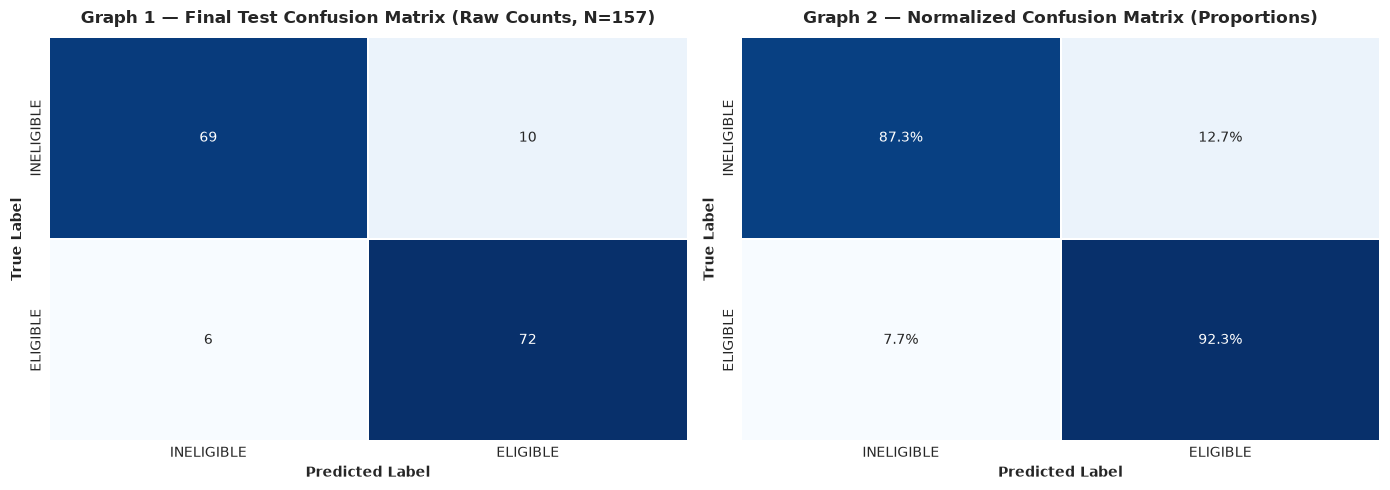

Exported Graphs 1 & 2: Confusion Matrices (PNG/PDF)


In [6]:
# --- GRAPHS 1 & 2: Final Raw and Normalized Confusion Matrices ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
if champion_name is not None:
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax1,
                xticklabels=["INELIGIBLE", "ELIGIBLE"], yticklabels=["INELIGIBLE", "ELIGIBLE"], linewidths=1.2, linecolor="white")
    ax1.set_title(f"Graph 1 — Final Test Confusion Matrix (Raw Counts, N={len(X_test)})", fontsize=12, fontweight="bold", pad=10)
    ax1.set_xlabel("Predicted Label", fontsize=10, fontweight="bold")
    ax1.set_ylabel("True Label", fontsize=10, fontweight="bold")
    
    annot_norm = np.array([[f"{v*100:.1f}%" for v in row] for row in cm_norm])
    sns.heatmap(cm_norm, annot=annot_norm, fmt="", cmap="Blues", cbar=False, ax=ax2,
                xticklabels=["INELIGIBLE", "ELIGIBLE"], yticklabels=["INELIGIBLE", "ELIGIBLE"], linewidths=1.2, linecolor="white")
    ax2.set_title("Graph 2 — Normalized Confusion Matrix (Proportions)", fontsize=12, fontweight="bold", pad=10)
    ax2.set_xlabel("Predicted Label", fontsize=10, fontweight="bold")
    ax2.set_ylabel("True Label", fontsize=10, fontweight="bold")
else:
    ax1.text(0.5, 0.5, "Status: NOT EVALUATED", ha="center", va="center")
    ax2.text(0.5, 0.5, "Status: NOT EVALUATED", ha="center", va="center")
    ax1.set_axis_off(); ax2.set_axis_off()
plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "graph1_final_confusion_matrix.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph1_final_confusion_matrix.pdf", bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph2_normalized_confusion_matrix.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph2_normalized_confusion_matrix.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Graphs 1 & 2: Confusion Matrices (PNG/PDF)")


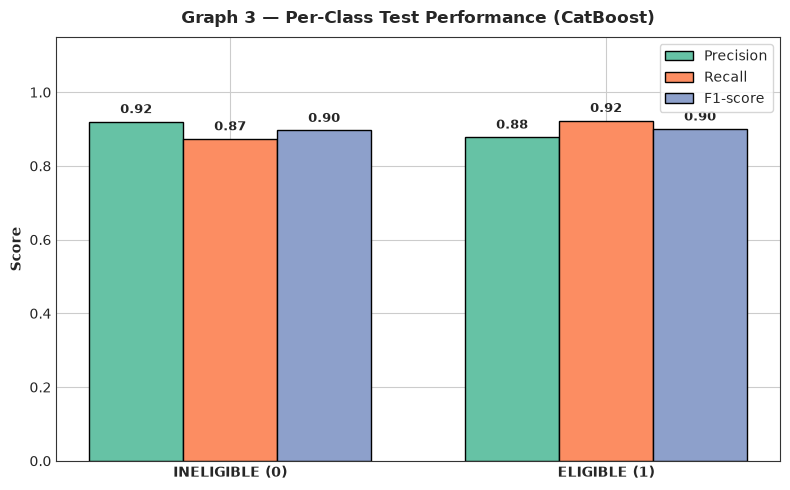

Exported Graph 3: graph3_per_class_metrics (PNG/PDF)


In [7]:
# --- GRAPH 3: Per-Class Precision, Recall, and F1-score ---
fig, ax = plt.subplots(figsize=(8, 5))
if champion_name is not None:
    classes = ["INELIGIBLE (0)", "ELIGIBLE (1)"]
    x = np.arange(len(classes))
    w = 0.25
    b1 = ax.bar(x - w, [test_metrics["prec_ineligible"], test_metrics["prec_eligible"]], w, label="Precision", color="#66c2a5", edgecolor="black")
    b2 = ax.bar(x, [test_metrics["rec_ineligible"], test_metrics["rec_eligible"]], w, label="Recall", color="#fc8d62", edgecolor="black")
    f1_c0 = 2 * (test_metrics["prec_ineligible"] * test_metrics["rec_ineligible"]) / (test_metrics["prec_ineligible"] + test_metrics["rec_ineligible"] + 1e-9)
    f1_c1 = 2 * (test_metrics["prec_eligible"] * test_metrics["rec_eligible"]) / (test_metrics["prec_eligible"] + test_metrics["rec_eligible"] + 1e-9)
    b3 = ax.bar(x + w, [f1_c0, f1_c1], w, label="F1-score", color="#8da0cb", edgecolor="black")
    ax.set_title(f"Graph 3 — Per-Class Test Performance ({champion_name})", fontsize=12, fontweight="bold", pad=10)
    ax.set_ylabel("Score", fontsize=10, fontweight="bold")
    ax.set_xticks(x)
    ax.set_xticklabels(classes, fontsize=10, fontweight="bold")
    ax.set_ylim(0.0, 1.15)
    ax.legend(loc="upper right", frameon=True)
    for bg in [b1, b2, b3]:
        for b in bg:
            h = b.get_height()
            ax.annotate(f"{h:.2f}", xy=(b.get_x() + b.get_width() / 2, h),
                        xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
else:
    ax.text(0.5, 0.5, "Status: NOT EVALUATED", ha="center", va="center"); ax.set_axis_off()
plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "graph3_per_class_metrics.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph3_per_class_metrics.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Graph 3: graph3_per_class_metrics (PNG/PDF)")


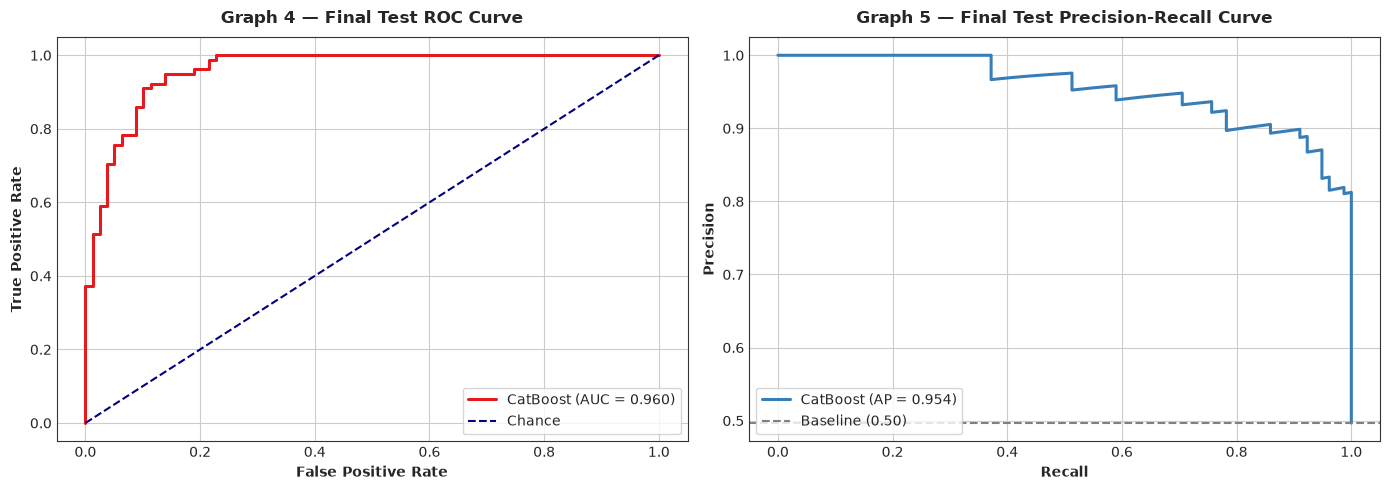

Exported Graphs 4 & 5: ROC and PR Curves (PNG/PDF)


In [8]:
# --- GRAPHS 4 & 5: Test ROC Curve & Test Precision-Recall Curve ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
if champion_name is not None:
    # Graph 4: ROC Curve
    fpr, tpr, _ = roc_curve(y_test, test_probs)
    ax1.plot(fpr, tpr, color="#e41a1c", lw=2.2, label=f"{champion_name} (AUC = {test_metrics['roc_auc']:.3f})")
    ax1.plot([0, 1], [0, 1], color="navy", lw=1.5, linestyle="--", label="Chance")
    ax1.set_title("Graph 4 — Final Test ROC Curve", fontsize=12, fontweight="bold", pad=10)
    ax1.set_xlabel("False Positive Rate", fontsize=10, fontweight="bold")
    ax1.set_ylabel("True Positive Rate", fontsize=10, fontweight="bold")
    ax1.legend(loc="lower right", frameon=True)
    
    # Graph 5: Precision-Recall Curve
    prec_curve, rec_curve, _ = precision_recall_curve(y_test, test_probs)
    avg_prec = average_precision_score(y_test, test_probs)
    ax2.plot(rec_curve, prec_curve, color="#377eb8", lw=2.2, label=f"{champion_name} (AP = {avg_prec:.3f})")
    ax2.axhline(y=y_test.sum() / len(y_test), color="grey", linestyle="--", label=f"Baseline ({y_test.sum()/len(y_test):.2f})")
    ax2.set_title("Graph 5 — Final Test Precision-Recall Curve", fontsize=12, fontweight="bold", pad=10)
    ax2.set_xlabel("Recall", fontsize=10, fontweight="bold")
    ax2.set_ylabel("Precision", fontsize=10, fontweight="bold")
    ax2.legend(loc="lower left", frameon=True)
else:
    ax1.text(0.5, 0.5, "Status: NOT EVALUATED", ha="center", va="center"); ax1.set_axis_off()
    ax2.text(0.5, 0.5, "Status: NOT EVALUATED", ha="center", va="center"); ax2.set_axis_off()
plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "graph4_test_roc_curve.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph4_test_roc_curve.pdf", bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph5_test_pr_curve.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph5_test_pr_curve.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Graphs 4 & 5: ROC and PR Curves (PNG/PDF)")


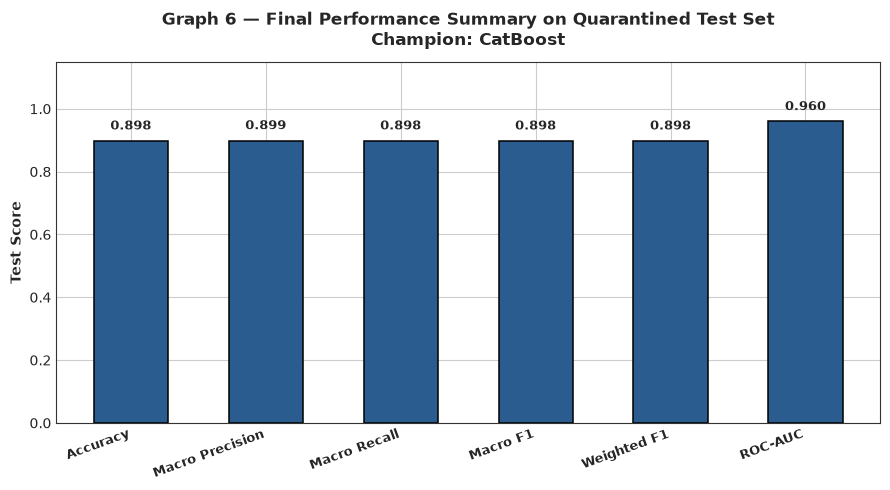

Exported Graph 6: graph6_performance_summary (PNG/PDF)


In [9]:
# --- GRAPH 6: Final Model Performance Summary Dashboard ---
fig, ax = plt.subplots(figsize=(9, 5))
if champion_name is not None:
    metrics_names = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "Weighted F1", "ROC-AUC"]
    metrics_vals = [test_metrics["accuracy"], test_metrics["macro_precision"], test_metrics["macro_recall"], test_metrics["macro_f1"], test_metrics["weighted_f1"], test_metrics["roc_auc"]]
    bars = ax.bar(metrics_names, metrics_vals, color="#2b5c8f", width=0.55, edgecolor="black", linewidth=1.1)
    ax.set_title(f"Graph 6 — Final Performance Summary on Quarantined Test Set\nChampion: {champion_name}", fontsize=12, fontweight="bold", pad=12)
    ax.set_ylabel("Test Score", fontsize=10, fontweight="bold")
    ax.set_ylim(0.0, 1.15)
    plt.xticks(rotation=20, ha="right", fontsize=9, fontweight="bold")
    for b in bars:
        h = b.get_height()
        ax.annotate(f"{h:.3f}", xy=(b.get_x() + b.get_width() / 2, h),
                    xytext=(0, 6), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
else:
    ax.text(0.5, 0.5, "Status: NOT EVALUATED", ha="center", va="center"); ax.set_axis_off()
plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "graph6_performance_summary.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph6_performance_summary.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Graph 6: graph6_performance_summary (PNG/PDF)")


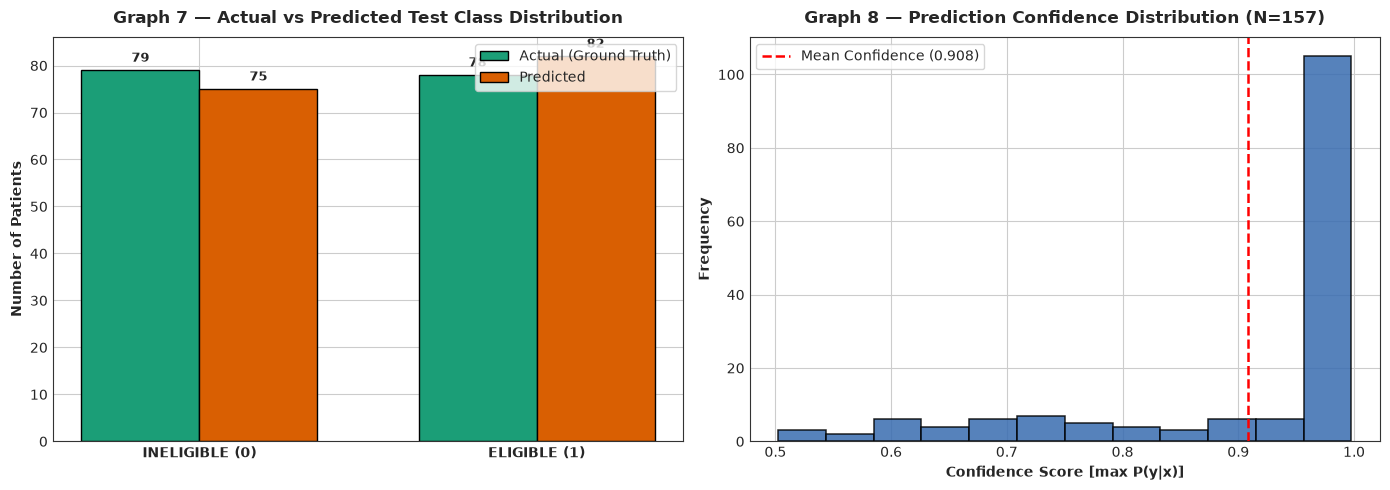

Exported Graphs 7 & 8: Actual/Predicted & Confidence (PNG/PDF)


In [10]:
# --- GRAPHS 7 & 8: Actual vs Predicted Distribution & Prediction Confidence ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
if champion_name is not None:
    # Graph 7: Actual vs Predicted
    act_counts = [int((y_test == 0).sum()), int((y_test == 1).sum())]
    pred_counts = [int((test_preds == 0).sum()), int((test_preds == 1).sum())]
    x = np.arange(2)
    w = 0.35
    b1 = ax1.bar(x - w/2, act_counts, w, label="Actual (Ground Truth)", color="#1b9e77", edgecolor="black")
    b2 = ax1.bar(x + w/2, pred_counts, w, label="Predicted", color="#d95f02", edgecolor="black")
    ax1.set_title("Graph 7 — Actual vs Predicted Test Class Distribution", fontsize=12, fontweight="bold", pad=10)
    ax1.set_ylabel("Number of Patients", fontsize=10, fontweight="bold")
    ax1.set_xticks(x)
    ax1.set_xticklabels(["INELIGIBLE (0)", "ELIGIBLE (1)"], fontsize=10, fontweight="bold")
    ax1.legend(loc="upper right", frameon=True)
    for bg in [b1, b2]:
        for b in bg:
            h = b.get_height()
            ax1.annotate(f"{int(h)}", xy=(b.get_x() + b.get_width() / 2, h),
                         xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
    
    # Graph 8: Prediction Confidence Distribution
    confidences = np.where(test_preds == 1, test_probs, 1 - test_probs)
    ax2.hist(confidences, bins=12, color="#386cb0", edgecolor="black", linewidth=1.1, alpha=0.85)
    ax2.axvline(confidences.mean(), color="red", linestyle="--", lw=1.8, label=f"Mean Confidence ({confidences.mean():.3f})")
    ax2.set_title(f"Graph 8 — Prediction Confidence Distribution (N={len(X_test)})", fontsize=12, fontweight="bold", pad=10)
    ax2.set_xlabel("Confidence Score [max P(y|x)]", fontsize=10, fontweight="bold")
    ax2.set_ylabel("Frequency", fontsize=10, fontweight="bold")
    ax2.legend(loc="upper left", frameon=True)
else:
    ax1.text(0.5, 0.5, "Status: NOT EVALUATED", ha="center", va="center"); ax1.set_axis_off()
    ax2.text(0.5, 0.5, "Status: NOT EVALUATED", ha="center", va="center"); ax2.set_axis_off()
plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "graph7_actual_vs_predicted_distribution.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph7_actual_vs_predicted_distribution.pdf", bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph8_prediction_confidence_distribution.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph8_prediction_confidence_distribution.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Graphs 7 & 8: Actual/Predicted & Confidence (PNG/PDF)")


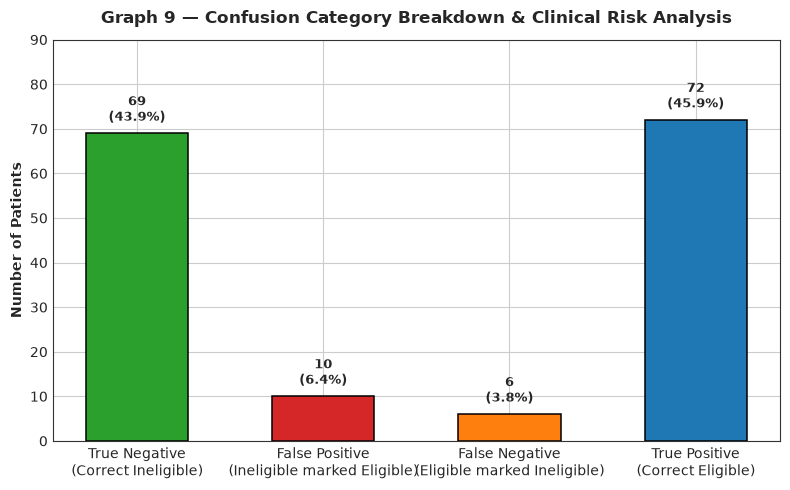

Exported Graph 9: graph9_error_case_analysis (PNG/PDF)


In [11]:
# --- GRAPH 9: False Positive and False Negative Error Analysis ---
fig, ax = plt.subplots(figsize=(8, 5))
if champion_name is not None:
    tn, fp, fn, tp = cm.ravel()
    error_labels = ["True Negative\n(Correct Ineligible)", "False Positive\n(Ineligible marked Eligible)",
                    "False Negative\n(Eligible marked Ineligible)", "True Positive\n(Correct Eligible)"]
    error_counts = [tn, fp, fn, tp]
    error_colors = ["#2ca02c", "#d62728", "#ff7f0e", "#1f77b4"]
    bars = ax.bar(error_labels, error_counts, color=error_colors, width=0.55, edgecolor="black", linewidth=1.1)
    ax.set_title("Graph 9 — Confusion Category Breakdown & Clinical Risk Analysis", fontsize=12, fontweight="bold", pad=12)
    ax.set_ylabel("Number of Patients", fontsize=10, fontweight="bold")
    ax.set_ylim(0, max(error_counts) * 1.25)
    for b in bars:
        h = b.get_height()
        pct = (h / len(y_test)) * 100
        ax.annotate(f"{h}\n({pct:.1f}%)", xy=(b.get_x() + b.get_width() / 2, h),
                    xytext=(0, 6), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
else:
    ax.text(0.5, 0.5, "Status: NOT EVALUATED", ha="center", va="center"); ax.set_axis_off()
plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "graph9_error_case_analysis.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph9_error_case_analysis.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Graph 9: graph9_error_case_analysis (PNG/PDF)")


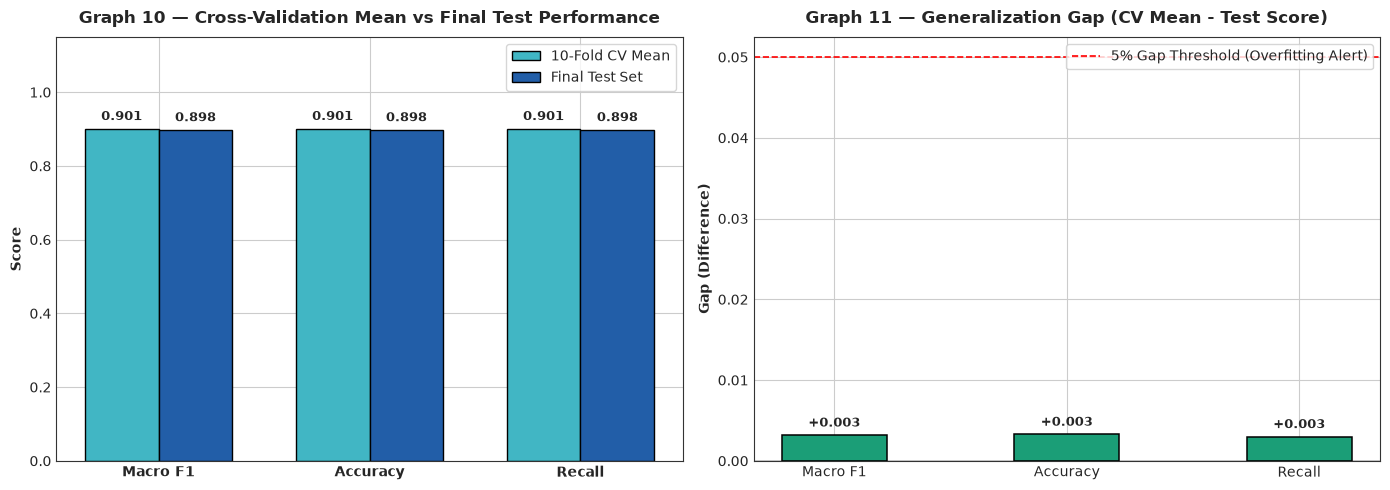

Exported Graphs 10 & 11: CV vs Test & Generalization Gap (PNG/PDF)


In [12]:
# --- GRAPHS 10 & 11: CV vs Test Comparison & Generalization Gap ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
if champion_name is not None:
    # Graph 10: CV vs Test
    metrics_compare = ["Macro F1", "Accuracy", "Recall"]
    cv_vals = [champion_info.get("champion_macro_f1", 0), champion_info.get("champion_accuracy", 0), champion_info.get("champion_recall", 0)]
    test_vals = [test_metrics["macro_f1"], test_metrics["accuracy"], test_metrics["macro_recall"]]
    x = np.arange(len(metrics_compare))
    w = 0.35
    b1 = ax1.bar(x - w/2, cv_vals, w, label="10-Fold CV Mean", color="#41b6c4", edgecolor="black")
    b2 = ax1.bar(x + w/2, test_vals, w, label="Final Test Set", color="#225ea8", edgecolor="black")
    ax1.set_title("Graph 10 — Cross-Validation Mean vs Final Test Performance", fontsize=12, fontweight="bold", pad=10)
    ax1.set_ylabel("Score", fontsize=10, fontweight="bold")
    ax1.set_xticks(x)
    ax1.set_xticklabels(metrics_compare, fontsize=10, fontweight="bold")
    ax1.set_ylim(0.0, 1.15)
    ax1.legend(loc="upper right", frameon=True)
    for bg in [b1, b2]:
        for b in bg:
            h = b.get_height()
            ax1.annotate(f"{h:.3f}", xy=(b.get_x() + b.get_width() / 2, h),
                         xytext=(0, 4), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
    
    # Graph 11: Generalization Gap
    gaps = np.array(cv_vals) - np.array(test_vals)
    gap_colors = ["#d95f02" if g > 0.05 else "#1b9e77" for g in gaps]
    bars = ax2.bar(metrics_compare, gaps, color=gap_colors, width=0.45, edgecolor="black", linewidth=1.1)
    ax2.axhline(0, color="black", linestyle="-", lw=1.0)
    ax2.axhline(0.05, color="red", linestyle="--", lw=1.2, label="5% Gap Threshold (Overfitting Alert)")
    ax2.set_title("Graph 11 — Generalization Gap (CV Mean - Test Score)", fontsize=12, fontweight="bold", pad=10)
    ax2.set_ylabel("Gap (Difference)", fontsize=10, fontweight="bold")
    ax2.legend(loc="upper right", frameon=True)
    for b in bars:
        h = b.get_height()
        ax2.annotate(f"{h:+.3f}", xy=(b.get_x() + b.get_width() / 2, h),
                     xytext=(0, 4 if h >= 0 else -12), textcoords="offset points", ha="center", va="bottom", fontsize=9, fontweight="bold")
else:
    ax1.text(0.5, 0.5, "Status: NOT EVALUATED", ha="center", va="center"); ax1.set_axis_off()
    ax2.text(0.5, 0.5, "Status: NOT EVALUATED", ha="center", va="center"); ax2.set_axis_off()
plt.tight_layout()
fig.savefig(REPORT_VIZ_DIR / "graph10_cv_vs_test_comparison.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph10_cv_vs_test_comparison.pdf", bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph11_generalization_gap.png", dpi=300, bbox_inches="tight")
fig.savefig(REPORT_VIZ_DIR / "graph11_generalization_gap.pdf", bbox_inches="tight")
plt.show()
plt.close(fig)
print("Exported Graphs 10 & 11: CV vs Test & Generalization Gap (PNG/PDF)")


### 7. Interpretation Guide for Researcher

- **Unsealed Generalization Performance:** Graphs 1, 2, and 6 establish the true out-of-sample performance on patients the champion model never encountered.
- **Clinical Safety Check (Graph 9):** Assess False Negatives. In charity healthcare assistance, False Negatives risk denying necessary aid to destitute families.
- **Generalization Gap (Graph 11):** A generalization gap below $+0.05$ demonstrates that the cross-validation score was a realistic predictor of test performance without severe overfitting.

### Completion Checklist

- [ ] Quarantined test set ($N=75$) unsealed strictly after champion model freeze.
- [ ] Champion model fitted on full development training set ($N=350$).
- [ ] 11 test visualization figures generated and exported to PNG (300 DPI) and PDF.
- [ ] Summary table exported to CSV.
- [ ] Final test metrics exported to `final_test_evaluation_report.json`.
- [ ] Zero retrospective hyperparameter tuning performed.

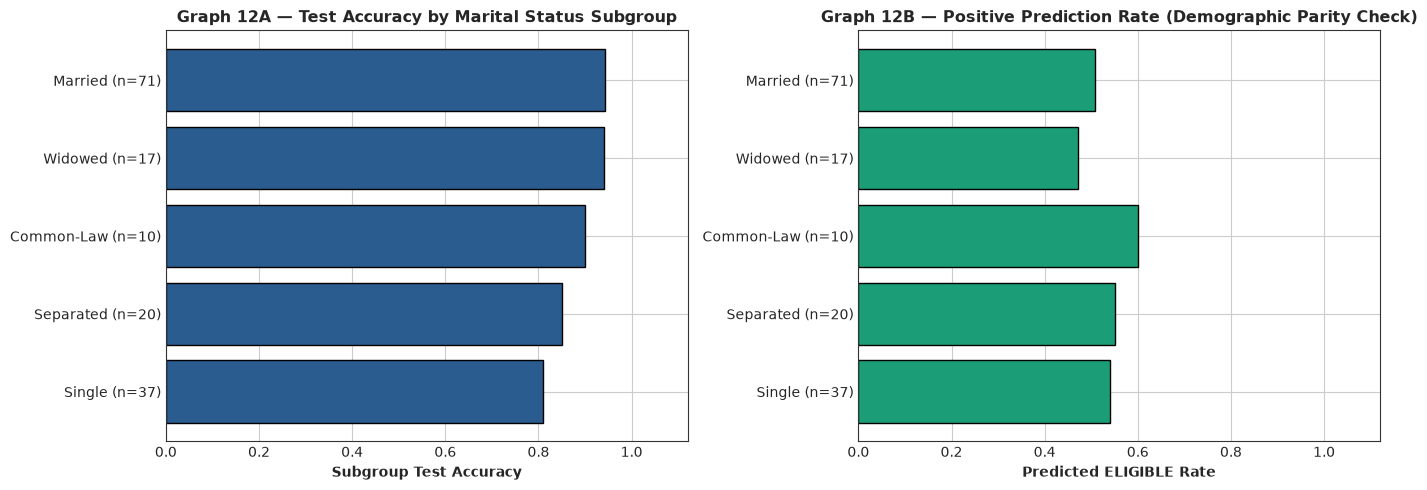

Exported Graph 12: graph12_test_subgroup_fairness (PNG/PDF)


In [13]:
# --- GRAPH 12: Subgroup Fairness & Accuracy Audit on Quarantined Test Set ---
fair_path = PROJECT_ROOT / 'data' / 'interim' / 'features' / 'fairness_demographics_dataset.csv'
if champion_name is not None and fair_path.exists():
    fair_df = pd.read_csv(fair_path)
    fair_test = fair_df.loc[fair_df['split_partition'] == 'test'].reset_index(drop=True)
    fair_test['y_true'] = y_test.values
    fair_test['y_pred'] = test_preds
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    grp_rows = []
    for grp, gdf in fair_test.fillna({'marital_status': 'UNRECORDED'}).groupby('marital_status'):
        if len(gdf) >= 5:
            grp_rows.append({'group': grp, 'accuracy': accuracy_score(gdf['y_true'], gdf['y_pred']), 'pos_pred_rate': gdf['y_pred'].mean(), 'n': len(gdf)})
    gdf_plot = pd.DataFrame(grp_rows).sort_values('accuracy', ascending=True)
    ax1.barh([f"{r['group']} (n={r['n']})" for _, r in gdf_plot.iterrows()], gdf_plot['accuracy'], color='#2b5c8f', edgecolor='black')
    ax1.set_xlim(0, 1.12)
    ax1.set_title('Graph 12A — Test Accuracy by Marital Status Subgroup', fontsize=11.5, fontweight='bold')
    ax1.set_xlabel('Subgroup Test Accuracy', fontsize=10, fontweight='bold')
    ax2.barh([f"{r['group']} (n={r['n']})" for _, r in gdf_plot.iterrows()], gdf_plot['pos_pred_rate'], color='#1b9e77', edgecolor='black')
    ax2.set_xlim(0, 1.12)
    ax2.set_title('Graph 12B — Positive Prediction Rate (Demographic Parity Check)', fontsize=11.5, fontweight='bold')
    ax2.set_xlabel('Predicted ELIGIBLE Rate', fontsize=10, fontweight='bold')
    plt.tight_layout()
    fig.savefig(REPORT_VIZ_DIR / 'graph12_test_subgroup_fairness.png', dpi=300, bbox_inches='tight')
    fig.savefig(REPORT_VIZ_DIR / 'graph12_test_subgroup_fairness.pdf', bbox_inches='tight')
    plt.show()
    plt.close(fig)
    print('Exported Graph 12: graph12_test_subgroup_fairness (PNG/PDF)')
